In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Return to the project root if the notebook is opened from the notebooks folder
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

# File paths
prof_data = "data/001MoDe_R1.csv"
personal_data = "data/data.csv"

# Load a dataset and calculate its sampling frequency
def load_dataset(file_path):

    with open(file_path, "r") as file:
        first_line = file.readline().strip()

    data = np.loadtxt(file_path, delimiter=",", skiprows=4)

    # Keep only valid samples
    data = data[data[:, 0] > 0]

    timestamps = data[:, 0]

    # Calculate sampling frequency
    time_differences = np.diff(timestamps)
    time_differences = time_differences[time_differences > 0]

    sampling_frequency = 1000 / np.median(time_differences)

    # Calculate recording duration
    duration = (timestamps[-1] - timestamps[0]) / 1000

    return {
        "data": data,
        "samples": len(data),
        "frequency": sampling_frequency,
        "duration": duration
    }

# Load both datasets
prof = load_dataset(prof_data)
personal = load_dataset(personal_data)

print("Professor dataset")
print("Number of samples:", prof["samples"])
print("Sampling frequency:", round(prof["frequency"], 2), "Hz")
print("Duration:", round(prof["duration"], 2), "seconds")

print("\nPersonal dataset")
print("Number of samples:", personal["samples"])
print("Sampling frequency:", round(personal["frequency"], 2), "Hz")
print("Duration:", round(personal["duration"], 2), "seconds")

Professor dataset
Number of samples: 19588
Sampling frequency: 200.0 Hz
Duration: 180.1 seconds

Personal dataset
Number of samples: 2202
Sampling frequency: 76.92 Hz
Duration: 108.26 seconds


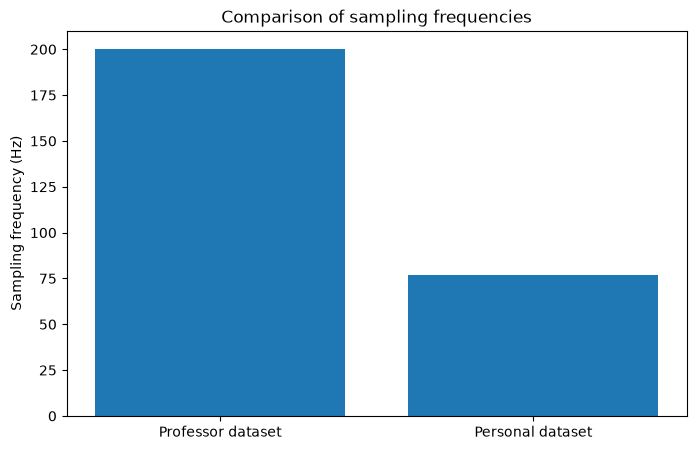

In [2]:
# Compare sampling frequencies

datasets = ["Professor dataset", "Personal dataset"]
frequencies = [prof["frequency"], personal["frequency"]]

plt.figure(figsize=(8, 5))

plt.bar(datasets, frequencies)

plt.ylabel("Sampling frequency (Hz)")
plt.title("Comparison of sampling frequencies")

plt.show()

In [3]:
# Paths to marker files
prof_marker = "data/001MoDe_R1.marker.csv"
personal_marker = "data/marker.csv"

# Display the first lines of each marker file
def inspect_marker_file(file_path):

    print("\nFile:", file_path)

    with open(file_path, "r") as file:
        for i in range(10):
            line = file.readline()
            if not line:
                break
            print(line.strip())

inspect_marker_file(prof_marker)
inspect_marker_file(personal_marker)


File: data/001MoDe_R1.marker.csv
screenWidth 1104;screenHeight 661;cornerX 302;cornerY 80;centerX 552;centerY 330;externalRadius 250;internalRadius 170;borderRadius 1;cursorRadius 16;indexOfDifficulty 28.00696429476858;taskRadius 209.5;taskTolerance 47;borderColor java.awt.Color[r=255,g=255,b=255];backgroundColor java.awt.Color[r=0,g=0,b=0];cursorColorRecord java.awt.Color[r=255,g=0,b=0];cursorColorWait java.awt.Color[r=255,g=255,b=0];autoStart 3600;cycleMaxNumber 6;cycleDuration 20;software LSL-mouse;version 1.2.0rc5;task CircularTarget;isWithLSL false
2021-03-26 17:38:25.650

2021-03-26 17:38:32.325,1616776712325,KeyTyped=32 DoCycleChange
2021-03-26 17:38:32.331,1616776712331,DoCycleChange:DoStartCycleTimedSequence
2021-03-26 17:38:32.333,1616776712333,DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
2021-03-26 17:38:52.336,1616776732336,DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
2021-03-26 17:39:12.340,1616776752340,DoCycleChange:DoRecord RecordDone=1 PauseDone=1 T

In [4]:
import re

def extract_cycles(file_path):

    cycles = []

    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:

            if "DoRecord" in line or "DoPause" in line:

                match = re.search(r"(\d{13}),", line)

                if match:
                    timestamp = int(match.group(1))

                    if "DoRecord" in line:
                        cycles.append({
                            "start": timestamp,
                            "end": None
                        })

                    elif "DoPause" in line and cycles:
                        if cycles[-1]["end"] is None:
                            cycles[-1]["end"] = timestamp

    return cycles


# Extract cycles from both marker files
prof_cycles = extract_cycles(prof_marker)
personal_cycles = extract_cycles(personal_marker)


# Display cycle durations
def display_cycles(cycles, name):

    print("\n", name)

    for i, cycle in enumerate(cycles):

        if cycle["end"] is not None:
            duration = (cycle["end"] - cycle["start"]) / 1000
            print(f"Cycle {i+1}: {duration:.2f} seconds")
        else:
            print(f"Cycle {i+1}: incomplete")


display_cycles(prof_cycles, "PROFESSOR")
display_cycles(personal_cycles, "PERSONAL")


 PROFESSOR
Cycle 1: 20.00 seconds
Cycle 2: 20.01 seconds
Cycle 3: 20.01 seconds
Cycle 4: 20.01 seconds
Cycle 5: 20.01 seconds

 PERSONAL
Cycle 1: 20.00 seconds
Cycle 2: 20.00 seconds
Cycle 3: 20.00 seconds
Cycle 4: 20.00 seconds
Cycle 5: 20.00 seconds


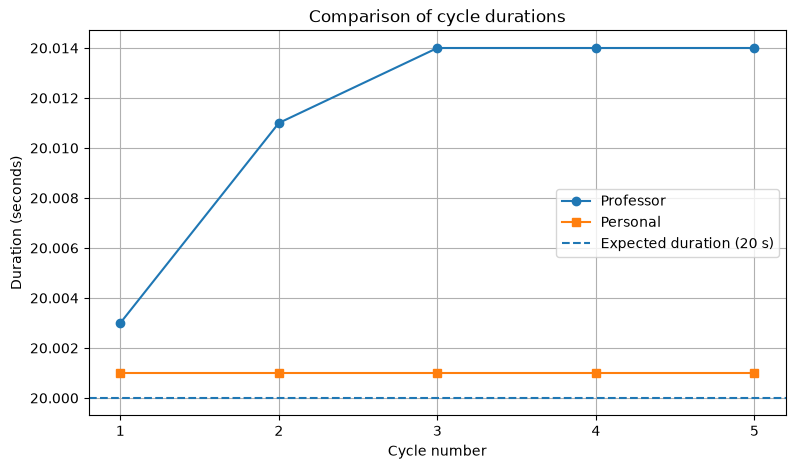

In [5]:
# Calculate cycle durations

def get_durations(cycles):
    return [
        (cycle["end"] - cycle["start"]) / 1000
        for cycle in cycles
        if cycle["end"] is not None
    ]


prof_durations = get_durations(prof_cycles)
personal_durations = get_durations(personal_cycles)

# Create the comparison plot

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(prof_durations) + 1),
    prof_durations,
    marker="o",
    label="Professor"
)

plt.plot(
    range(1, len(personal_durations) + 1),
    personal_durations,
    marker="s",
    label="Personal"
)

plt.axhline(
    y=20,
    linestyle="--",
    label="Expected duration (20 s)"
)

plt.xlabel("Cycle number")
plt.ylabel("Duration (seconds)")
plt.title("Comparison of cycle durations")
plt.xticks(range(1, 6))
plt.legend()
plt.grid()

plt.show()